<a href="https://colab.research.google.com/github/nisaerdemli/imageprocessing/blob/main/hafta10g%C3%B6rev2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Bulunan gorseller: ['scene1.row3.col1.ppm', 'scene1.row3.col2.ppm', 'scene1.row3.col3.ppm', 'scene1.row3.col4.ppm', 'scene1.row3.col5.ppm', 'truedisp.row3.col3.pgm']


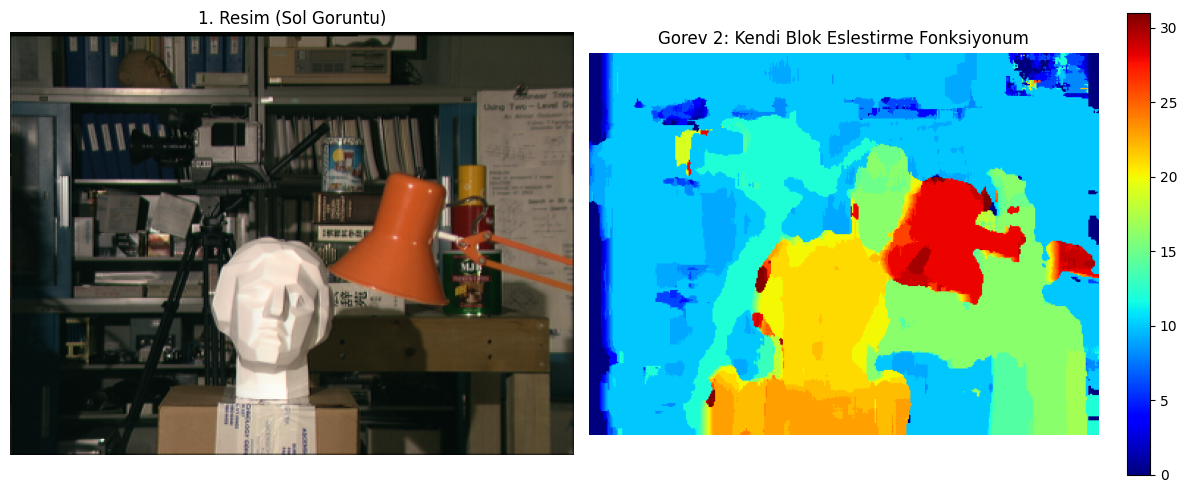

In [4]:
from pathlib import Path
import urllib.request
import zipfile
import cv2
import matplotlib.pyplot as plt
import numpy as np

url = "https://vision.middlebury.edu/stereo/data/scenes2001/data/tsukuba/tsukuba.zip"
zip_path = Path("tsukuba.zip")
extract_dir = Path("tsukuba_data")

# Klasor yoksa veya icinde yeterli gorsel yoksa indir ve cikart
valid_exts = {".ppm", ".pgm", ".png", ".jpg", ".jpeg"}
img_files = (
    sorted([p for p in extract_dir.rglob("*") if p.suffix.lower() in valid_exts])
    if extract_dir.exists()
    else []
)

if len(img_files) < 3:
  if zip_path.exists() and not zipfile.is_zipfile(zip_path):
    zip_path.unlink()

  if not zip_path.exists():
    req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(req, timeout=30) as resp, open(
        zip_path, "wb"
    ) as f:
      f.write(resp.read())

  with zipfile.ZipFile(zip_path, "r") as zf:
    zf.extractall(extract_dir)

  img_files = sorted(
      [p for p in extract_dir.rglob("*") if p.suffix.lower() in valid_exts]
  )

print("Bulunan gorseller:", [p.name for p in img_files])
assert (
    len(img_files) >= 3
), f"Yeterli gorsel bulunamadi. Klasor icerigi: {[p.name for p in extract_dir.rglob('*')]}"

# 1. ve 3. resimleri al
left_img = cv2.imread(str(img_files[0]))
right_img = cv2.imread(str(img_files[2]))
assert left_img is not None and right_img is not None, "Resimler okunamadi."

left_gray = cv2.cvtColor(left_img, cv2.COLOR_BGR2GRAY).astype(np.float32)
right_gray = cv2.cvtColor(right_img, cv2.COLOR_BGR2GRAY).astype(np.float32)


def my_block_matching(
    left: np.ndarray,
    right: np.ndarray,
    block_size: int = 15,
    max_disparity: int = 32,
) -> np.ndarray:
  h, w = left.shape
  cost_volume = np.full((h, w, max_disparity), np.inf, dtype=np.float32)
  kernel = (block_size, block_size)

  for d in range(max_disparity):
    if d == 0:
      diff = np.abs(left - right)
    else:
      shifted_right = np.zeros_like(right)
      shifted_right[:, d:] = right[:, :-d]
      diff = np.abs(left - shifted_right)

    block_sad = cv2.boxFilter(
        diff, ddepth=-1, ksize=kernel, normalize=False
    )
    cost_volume[:, :, d] = block_sad

  return np.argmin(cost_volume, axis=2).astype(np.float32)


disp_custom = my_block_matching(
    left_gray, right_gray, block_size=15, max_disparity=32
)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(cv2.cvtColor(left_img, cv2.COLOR_BGR2RGB))
axes[0].set_title("1. Resim (Sol Goruntu)")
axes[0].axis("off")

im = axes[1].imshow(disp_custom, cmap="jet")
axes[1].set_title("Gorev 2: Kendi Blok Eslestirme Fonksiyonum")
axes[1].axis("off")
plt.colorbar(im, ax=axes[1], fraction=0.046)

plt.tight_layout()
plt.show()